# Machine Learning Zoomcamp 2026
## Homework 4: Evaluation Metrics for Classification

En esta tarea evaluamos modelos de clasificación binaria usando el dataset **Lead Scoring 2026** ([course_lead_scoring_2026.csv](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)).

El objetivo de la clasificación es predecir la variable `converted` (si el usuario se inscribió o no en la plataforma).

### Métricas y conceptos abordados:
1. **ROC AUC Feature Importance**: Evaluación de la capacidad predictiva individual de variables numéricas.
2. **Entrenamiento de Regresión Logística**: Vectorización con `DictVectorizer` y cálculo del AUC en validación.
3. **Precision y Recall**: Cálculo de métricas en múltiples umbrales y punto de intersección.
4. **F1-Score**: Trade-off entre precisión y recall, y selección del umbral óptimo.
5. **K-Fold Cross-Validation (5 Folds)**: Evaluación de estabilidad y desviación estándar del AUC.
6. **Hyperparameter Tuning**: Búsqueda del mejor parámetro de regularización $C$ mediante validación cruzada.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)

%matplotlib inline


## Carga y Preparación de Datos

* Comprobar si hay valores nulos en las características.
* Si hay valores nulos:
  * Para variables categóricas, reemplazar con `'NA'`.
  * Para variables numéricas, reemplazar con `0.0`.
* Dividir el dataset en 3 partes:
  * `df_full_train` (80%) y `df_test` (20%) con `random_state=1`.
  * `df_train` (60% del total) y `df_val` (20% del total) a partir de `df_full_train` con `test_size=0.25` y `random_state=1`.


In [2]:
local_csv = '../../cohorts/2026/data/course_lead_scoring_2026.csv'
url_csv = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

if os.path.exists(local_csv):
    df = pd.read_csv(local_csv)
    print(f"Cargado desde archivo local: {local_csv}")
else:
    df = pd.read_csv(url_csv)
    print(f"Cargado desde URL: {url_csv}")

print(f"Forma del dataset: {df.shape}")
df.head()


Cargado desde archivo local: ../../cohorts/2026/data/course_lead_scoring_2026.csv
Forma del dataset: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
# Inspección de valores nulos
df.isnull().sum()


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
target = 'converted'
feature_cols = [c for c in df.columns if c != target]

categorical = df[feature_cols].select_dtypes(include=['object']).columns.tolist()
numerical = df[feature_cols].select_dtypes(exclude=['object']).columns.tolist()

print(f"Variables categóricas ({len(categorical)}): {categorical}")
print(f"Variables numéricas ({len(numerical)}): {numerical}")

# Reemplazo de nulos
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print(f"Total valores nulos restantes: {df.isnull().sum().sum()}")


Variables categóricas (4): ['lead_source', 'industry', 'employment_status', 'location']
Variables numéricas (4): ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Total valores nulos restantes: 0


C:\Users\aldaj\AppData\Local\Temp\ipykernel_9312\1973542206.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df[feature_cols].select_dtypes(include=['object']).columns.tolist()


In [5]:
# División del conjunto de datos con las llamadas exactas del enunciado:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reseteo de índices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Separación del target
y_train = df_train.pop('converted').values
y_val = df_val.pop('converted').values
y_test = df_test.pop('converted').values
y_full_train = df_full_train['converted'].values

print(f"df_train: {len(df_train)} filas ({len(df_train)/len(df):.0%})")
print(f"df_val:   {len(df_val)} filas ({len(df_val)/len(df):.0%})")
print(f"df_test:  {len(df_test)} filas ({len(df_test)/len(df):.0%})")


df_train: 3000 filas (60%)
df_val:   1000 filas (20%)
df_test:  1000 filas (20%)


---
### Question 1: ROC AUC feature importance

ROC AUC también puede utilizarse para evaluar la importancia de las variables numéricas:
* Para cada variable numérica, usarla como puntuación (predicción) y calcular el AUC con respecto a `y` (target).
* Utilizar el conjunto de entrenamiento (`df_train`).
* Si el AUC es $< 0.5$, invertir la variable anteponiendo un signo menos (`-df_train[col]`), convirtiendo la correlación negativa en positiva.

**¿Qué variable numérica (entre las siguientes 4) tiene el mayor AUC?**
* `lead_score`
* `number_of_courses_viewed`
* `interaction_count`
* `annual_income`


lead_score                 | AUC original: 0.7882 | AUC ajustado: 0.7882 [original (+)]
number_of_courses_viewed   | AUC original: 0.7230 | AUC ajustado: 0.7230 [original (+)]
interaction_count          | AUC original: 0.7649 | AUC ajustado: 0.7649 [original (+)]
annual_income              | AUC original: 0.6082 | AUC ajustado: 0.6082 [original (+)]


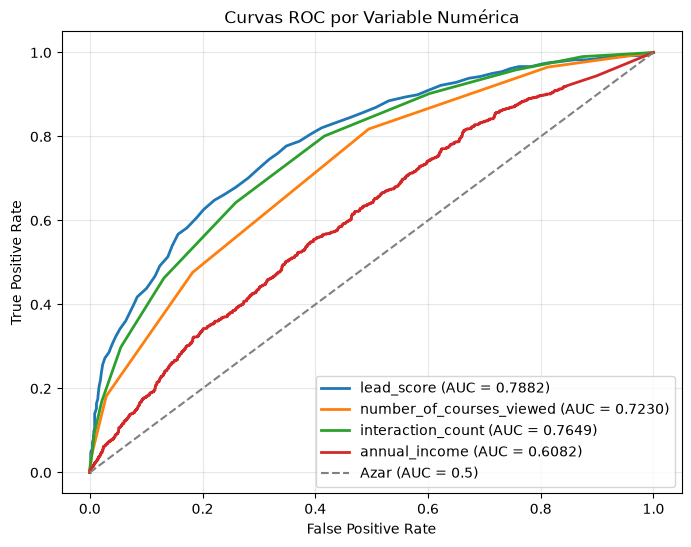


Variable con mayor AUC: 'lead_score' con AUC = 0.7882


In [6]:
candidates_q1 = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

auc_results = {}
plt.figure(figsize=(8, 6))

for col in candidates_q1:
    raw_auc = roc_auc_score(y_train, df_train[col])
    if raw_auc < 0.5:
        adj_auc = roc_auc_score(y_train, -df_train[col])
        fpr, tpr, _ = roc_curve(y_train, -df_train[col])
        direction = "invertida (-)"
    else:
        adj_auc = raw_auc
        fpr, tpr, _ = roc_curve(y_train, df_train[col])
        direction = "original (+)"
    
    auc_results[col] = adj_auc
    plt.plot(fpr, tpr, lw=2, label=f"{col} (AUC = {adj_auc:.4f})")
    print(f"{col:26s} | AUC original: {raw_auc:.4f} | AUC ajustado: {adj_auc:.4f} [{direction}]")

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Azar (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curvas ROC por Variable Numérica')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

best_feature = max(auc_results, key=auc_results.get)
print(f"\nVariable con mayor AUC: '{best_feature}' con AUC = {auc_results[best_feature]:.4f}")


**Respuesta Question 1:** **`lead_score`** (AUC = **0.7882**)


---
### Question 2: Training the model

* Aplicar One-Hot-Encoding con `DictVectorizer`.
* Entrenar una regresión logística con estos parámetros:
  ```python
  LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
  ```
* ¿Cuál es el AUC de este modelo en el dataset de validación? (redondeado a 3 dígitos)
  * 0.532
  * 0.632
  * 0.732
  * 0.832


In [7]:
# DictVectorizer
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
val_dict = df_val.to_dict(orient='records')

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

# Entrenamiento
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Predicción de probabilidades en validación
y_pred_val = model.predict_proba(X_val)[:, 1]

# Cálculo de AUC
val_auc = roc_auc_score(y_val, y_pred_val)
print(f"Validation AUC (preciso):   {val_auc:.4f}")
print(f"Validation AUC (redondeado): {val_auc:.3f}")


Validation AUC (preciso):   0.7318
Validation AUC (redondeado): 0.732


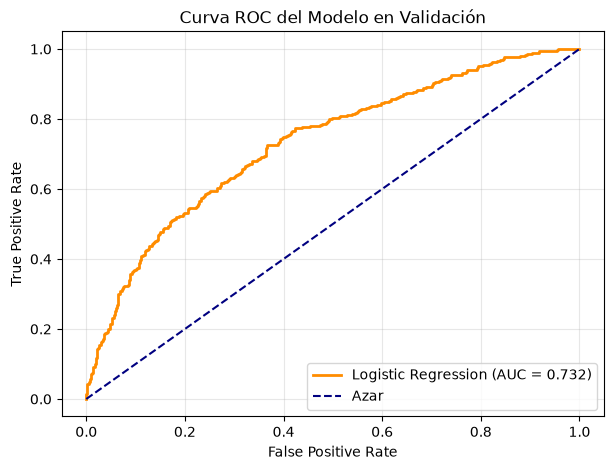

In [8]:
# Gráfica de la curva ROC del modelo
fpr, tpr, _ = roc_curve(y_val, y_pred_val)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Logistic Regression (AUC = {val_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Azar')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC del Modelo en Validación')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()


**Respuesta Question 2:** **`0.732`**


---
### Question 3: Precision and Recall

* Evaluar el modelo en todos los umbrales de 0.0 a 1.0 con paso 0.01.
* Para cada umbral, calcular precisión y recall.
* Graficar ambas curvas.
* ¿En qué umbral se intersecan las curvas de precisión y recall? (Elegir el umbral con la menor diferencia absoluta entre precisión y recall).
  * 0.43
  * 0.63
  * 0.73
  * 0.83


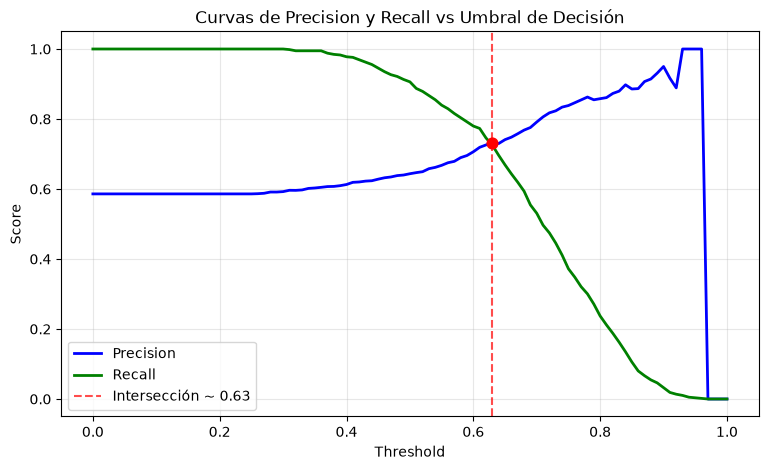

Menor diferencia |P - R|: 0.0075 en umbral: 0.63
Precision: 0.7328, Recall: 0.7253


In [9]:
thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []
diff_metrics = []

for t in thresholds:
    pred = (y_pred_val >= t).astype(int)
    p = precision_score(y_val, pred, zero_division=0)
    r = recall_score(y_val, pred, zero_division=0)
    precisions.append(p)
    recalls.append(r)
    
    # Ignorar umbrales donde ambas métricas son 0
    if p > 0 or r > 0:
        diff_metrics.append((abs(p - r), t, p, r))

# Umbral con menor diferencia absoluta
diff_metrics.sort()
min_diff, intersect_t, p_intersect, r_intersect = diff_metrics[0]

# Gráfica
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label='Precision', color='blue', lw=2)
plt.plot(thresholds, recalls, label='Recall', color='green', lw=2)
plt.axvline(x=intersect_t, color='red', linestyle='--', alpha=0.7, label=f'Intersección ~ {intersect_t:.2f}')
plt.scatter([intersect_t], [p_intersect], color='red', zorder=5, s=60)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Curvas de Precision y Recall vs Umbral de Decisión')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Menor diferencia |P - R|: {min_diff:.4f} en umbral: {intersect_t:.2f}")
print(f"Precision: {p_intersect:.4f}, Recall: {r_intersect:.4f}")


**Respuesta Question 3:** **`0.63`**


---
### Question 4: F1 score

Precision y recall son métricas contrapuestas. Se combinan en la métrica **F1 score**:

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

* Calcular F1 para todos los umbrales de 0.0 a 1.0 con incremento 0.01.
* ¿En qué umbral es máximo el F1?
  * 0.21
  * 0.41
  * 0.61
  * 0.81


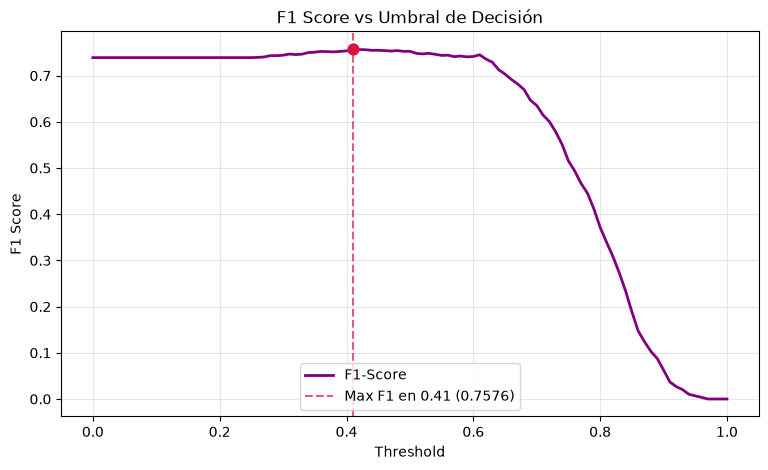

F1 máximo: 0.7576 alcanzado en el umbral: 0.41


In [10]:
f1_scores = []

for t in thresholds:
    pred = (y_pred_val >= t).astype(int)
    score = f1_score(y_val, pred, zero_division=0)
    f1_scores.append((score, t))

best_f1, best_threshold = max(f1_scores)

# Gráfica
plt.figure(figsize=(9, 5))
plt.plot(thresholds, [item[0] for item in f1_scores], color='purple', lw=2, label='F1-Score')
plt.axvline(x=best_threshold, color='crimson', linestyle='--', alpha=0.7, label=f'Max F1 en {best_threshold:.2f} ({best_f1:.4f})')
plt.scatter([best_threshold], [best_f1], color='crimson', zorder=5, s=60)

plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Umbral de Decisión')
plt.legend(loc='lower center')
plt.grid(True, alpha=0.3)
plt.show()

print(f"F1 máximo: {best_f1:.4f} alcanzado en el umbral: {best_threshold:.2f}")


**Respuesta Question 4:** **`0.41`**


---
### Question 5: 5-Fold CV

Usar la clase `KFold` de Scikit-Learn para evaluar el modelo en 5 folds diferentes:
```python
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterar sobre los diferentes folds de `df_full_train`.
* Dividir los datos en train y validation.
* Entrenar el modelo con `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`.
* Usar AUC para evaluar el modelo en validación.

**¿Qué tan grande es la desviación estándar de los puntajes entre los diferentes folds?**
* 0.001
* 0.007
* 0.013
* 0.060


In [11]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
cv_scores = []

features_full_train = df_full_train.drop(columns=['converted'])

for fold, (train_idx, val_idx) in enumerate(kfold.split(features_full_train), start=1):
    f_train = features_full_train.iloc[train_idx]
    f_val = features_full_train.iloc[val_idx]
    y_f_train = y_full_train[train_idx]
    y_f_val = y_full_train[val_idx]
    
    dv_fold = DictVectorizer(sparse=False)
    X_f_train = dv_fold.fit_transform(f_train.to_dict(orient='records'))
    X_f_val = dv_fold.transform(f_val.to_dict(orient='records'))
    
    model_fold = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model_fold.fit(X_f_train, y_f_train)
    
    preds = model_fold.predict_proba(X_f_val)[:, 1]
    score = roc_auc_score(y_f_val, preds)
    cv_scores.append(score)
    print(f"Fold {fold}: AUC = {score:.4f}")

mean_score = np.mean(cv_scores)
std_score = np.std(cv_scores)

print(f"\nAUC Medio: {mean_score:.4f}")
print(f"Desviación estándar: {std_score:.4f} -> Redondeado a 3 dígitos: {std_score:.3f}")


Fold 1: AUC = 0.7306
Fold 2: AUC = 0.7296
Fold 3: AUC = 0.7363


Fold 4: AUC = 0.7412
Fold 5: AUC = 0.7209

AUC Medio: 0.7317
Desviación estándar: 0.0069 -> Redondeado a 3 dígitos: 0.007


**Respuesta Question 5:** **`0.007`**


---
### Question 6: Hyperparameter Tuning

Utilizar 5-Fold Cross-Validation para encontrar el mejor parámetro `C`:
* Iterar sobre los valores de `C`: `[0.000001, 0.001, 1]`
* Inicializar `KFold` con los mismos parámetros previos.
* Usar `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`.
* Calcular la media y desviación estándar de ROC AUC (redondeando a 3 decimales).
* ¿Qué valor de `C` produce el mejor ROC AUC medio?
  * 0.000001
  * 0.001
  * 1


In [12]:
c_values = [0.000001, 0.001, 1]
tuning_results = []

for c in c_values:
    scores = []
    for train_idx, val_idx in kfold.split(features_full_train):
        f_train = features_full_train.iloc[train_idx]
        f_val = features_full_train.iloc[val_idx]
        y_f_train = y_full_train[train_idx]
        y_f_val = y_full_train[val_idx]
        
        dv_fold = DictVectorizer(sparse=False)
        X_f_train = dv_fold.fit_transform(f_train.to_dict(orient='records'))
        X_f_val = dv_fold.transform(f_val.to_dict(orient='records'))
        
        model_fold = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
        model_fold.fit(X_f_train, y_f_train)
        
        preds = model_fold.predict_proba(X_f_val)[:, 1]
        scores.append(roc_auc_score(y_f_val, preds))
    
    mean_val = np.mean(scores)
    std_val = np.std(scores)
    tuning_results.append({
        'C': c,
        'mean_auc_round': round(mean_val, 3),
        'std_auc_round': round(std_val, 3),
        'mean_auc_raw': mean_val,
        'std_auc_raw': std_val
    })
    print(f"C = {c:8g} | AUC medio = {mean_val:.4f} (redondeado: {round(mean_val, 3):.3f}) | std = {std_val:.4f} (redondeado: {round(std_val, 3):.3f})")

summary_df = pd.DataFrame(tuning_results)
summary_df


C =    1e-06 | AUC medio = 0.6167 (redondeado: 0.617) | std = 0.0187 (redondeado: 0.019)


C =    0.001 | AUC medio = 0.7492 (redondeado: 0.749) | std = 0.0100 (redondeado: 0.010)


C =        1 | AUC medio = 0.7317 (redondeado: 0.732) | std = 0.0069 (redondeado: 0.007)

,C,mean_auc_round,std_auc_round,mean_auc_raw,std_auc_raw
0,0.000001,0.617,0.019,0.616734,0.018670
1,0.001000,0.749,0.010,0.749172,0.009996
2,1.000000,0.732,0.007,0.731727,0.006853


In [13]:
# Criterio: mayor mean_auc, menor std_auc en caso de empate, menor C si persiste
best_choice = max(tuning_results, key=lambda x: (x['mean_auc_round'], -x['std_auc_round'], -x['C']))
print(f"Mejor parámetro C: {best_choice['C']} con ROC AUC medio de {best_choice['mean_auc_round']:.3f}")


Mejor parámetro C: 0.001 con ROC AUC medio de 0.749


**Respuesta Question 6:** **`0.001`**

---
## Resumen Final de Respuestas

| Pregunta | Opción Seleccionada | Detalle Numérico |
| :--- | :--- | :--- |
| **Q1: Feature importance con ROC AUC** | **`lead_score`** | Mayor AUC individual (0.7882) |
| **Q2: AUC del modelo en validación** | **`0.732`** | 0.7318... redondeado a 3 decimales |
| **Q3: Intersección Precision y Recall** | **`0.63`** | Diferencia mínima |P - R| = 0.0075 |
| **Q4: Umbral con F1-Score máximo** | **`0.41`** | F1 máximo = 0.7576 |
| **Q5: Desviación estándar 5-Fold CV** | **`0.007`** | Std dev = 0.0069... redondeado a 3 decimales |
| **Q6: Mejor regularización C** | **`0.001`** | Mayor AUC medio (0.749 vs 0.732 y 0.617) |
